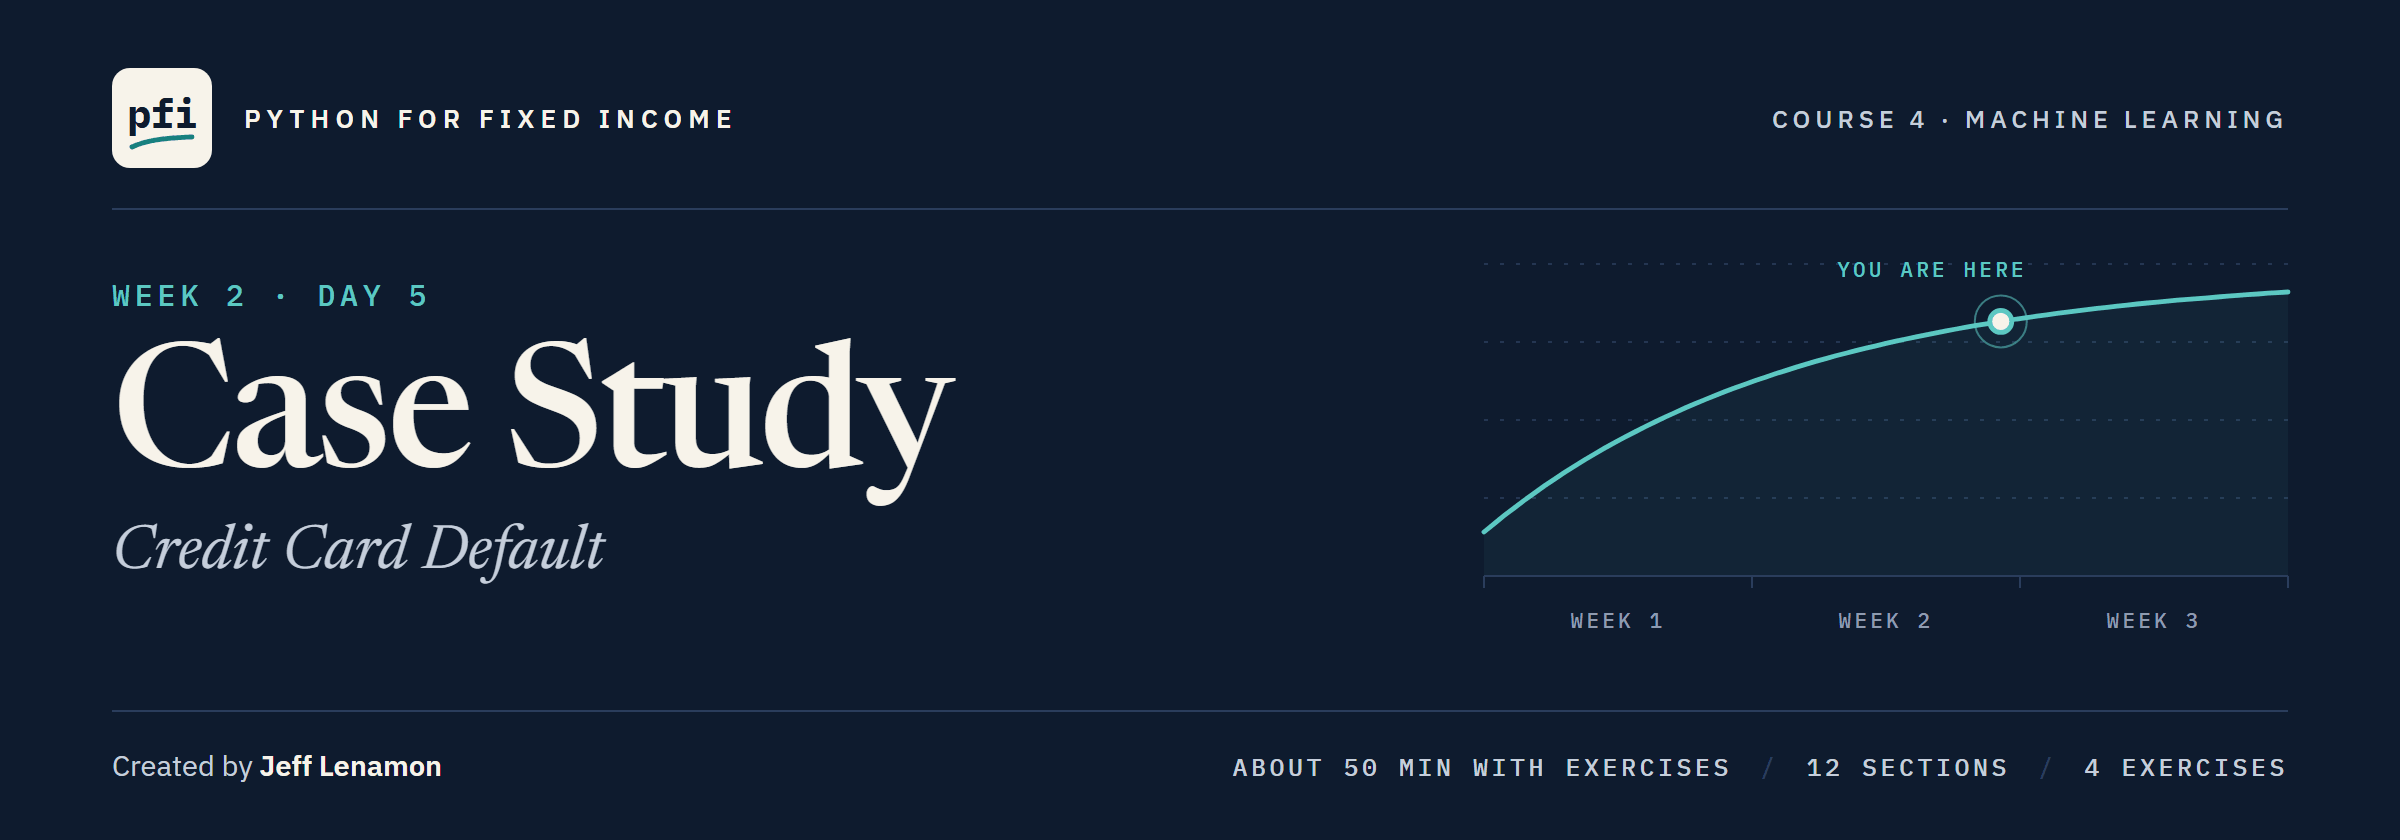

# Case Study: Credit Card Default

Week 2, Day 5. Run the whole job once on the card accounts: tame the heavy tails, fit a logistic regression and two trees, choose a model and a threshold on validation accounts, open the test accounts once, and say where the model fails.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week2/day5/10_case_study_credit_card_default.ipynb)

# Problem Statement

## Business Context

Days 6 to 9 built the pieces: odds, the confusion matrix, a threshold chosen for a recall target, a pruned tree.
Today the desk runs the whole job once, as a write-up would.
Which model ranks the accounts that defaulted highest, how many accounts must it flag to catch 70 percent of them, and what does it miss?
The accounts are real, from Taiwan, April to September 2005, so they describe consumer credit there and then, not US credit today.
`SEX`, `EDUCATION`, `MARRIAGE` and `AGE` are never features: a model using them would sort people by them, and leaving them out does not make a model neutral, because other columns can carry the same information.
A flag means "flagged at threshold t", never a credit decision about anyone.

## Objectives

Tame the heavy-tailed amounts, fit a logistic regression and two trees, and choose on validation accounts a threshold that catches 70 percent of the defaults.
Pick one model, open the test accounts once, describe its flags by the `SEX` label, and say where it fails.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as on Day 6)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never features

## Your Route Through Day 5

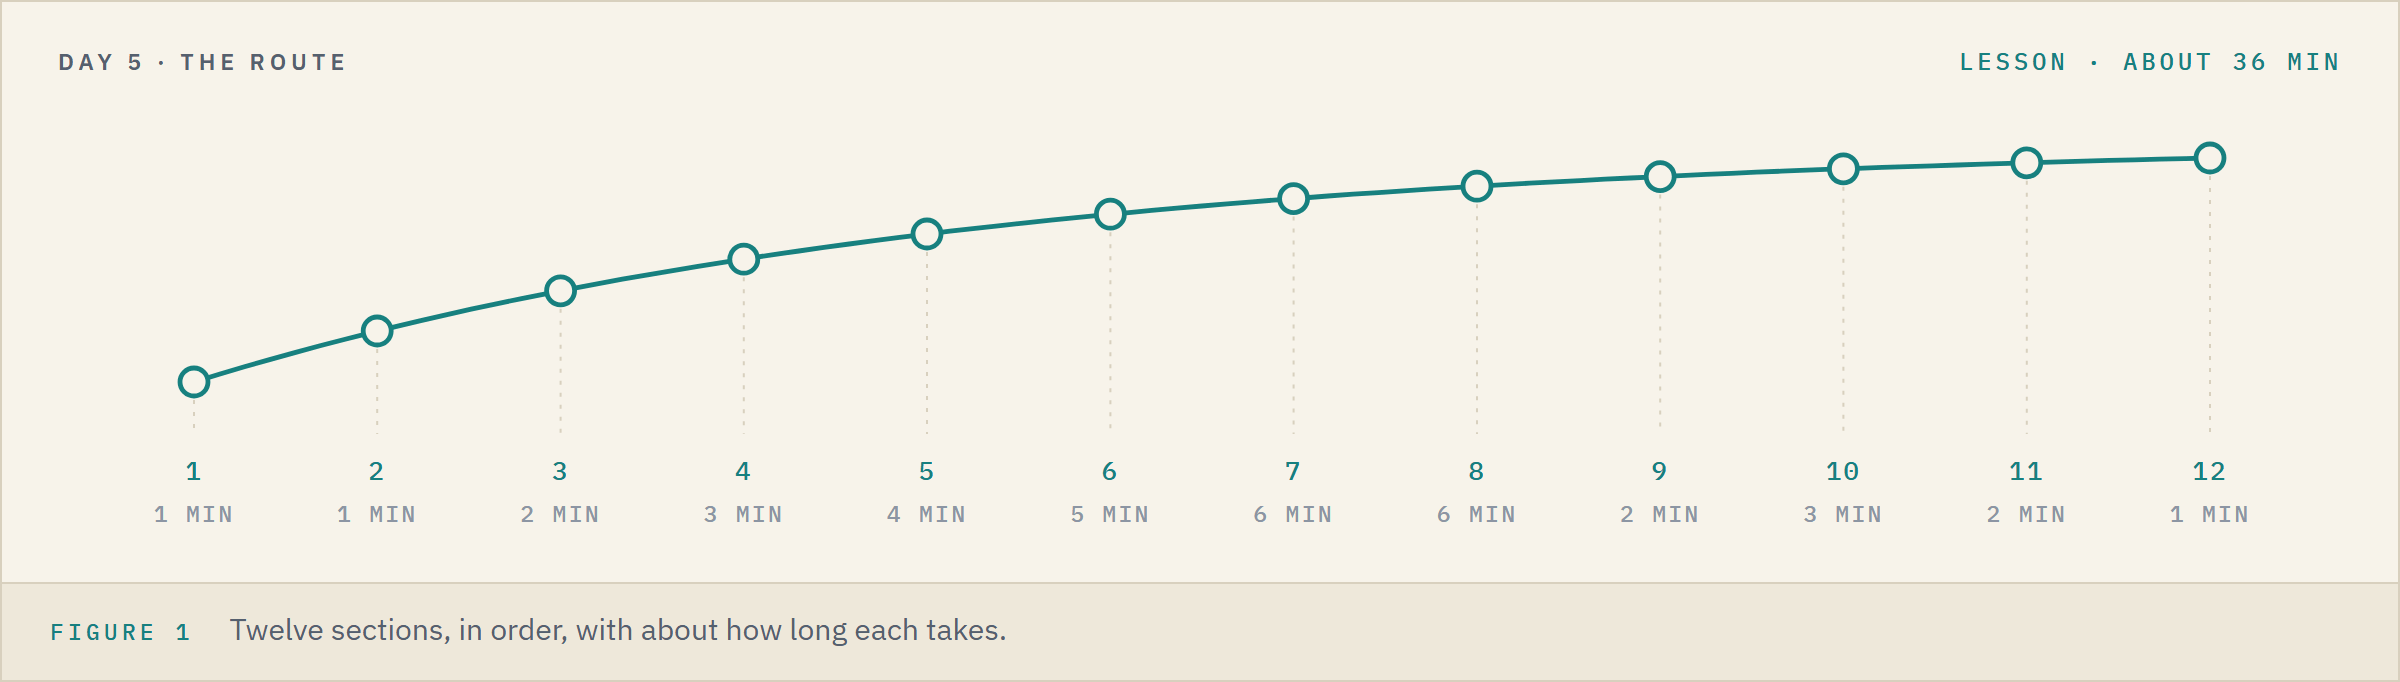

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1</td><td align="left">Setting Up</td><td align="left">1 min</td></tr>
<tr><td align="left">2</td><td align="left">Loading the Data</td><td align="left">1 min</td></tr>
<tr><td align="left">3</td><td align="left">Data Overview</td><td align="left">2 min</td></tr>
<tr><td align="left">4</td><td align="left">Exploratory Data Analysis</td><td align="left">3 min</td></tr>
<tr><td align="left">5</td><td align="left">Data Preparation for Modeling</td><td align="left">4 min</td></tr>
<tr><td align="left">6</td><td align="left">Model Building</td><td align="left">5 min</td></tr>
<tr><td align="left">7</td><td align="left">Model Performance Improvement</td><td align="left">6 min</td></tr>
<tr><td align="left">8</td><td align="left">Final Model Selection</td><td align="left">6 min</td></tr>
<tr><td align="left">9</td><td align="left">The Test Rows, Opened Once</td><td align="left">2 min</td></tr>
<tr><td align="left">10</td><td align="left">The Person Columns</td><td align="left">3 min</td></tr>
<tr><td align="left">11</td><td align="left">Where the Model Fails</td><td align="left">2 min</td></tr>
<tr><td align="left">12</td><td align="left">Insights and Conclusion</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 36 minutes for the lesson, then about 12 for the four exercises.

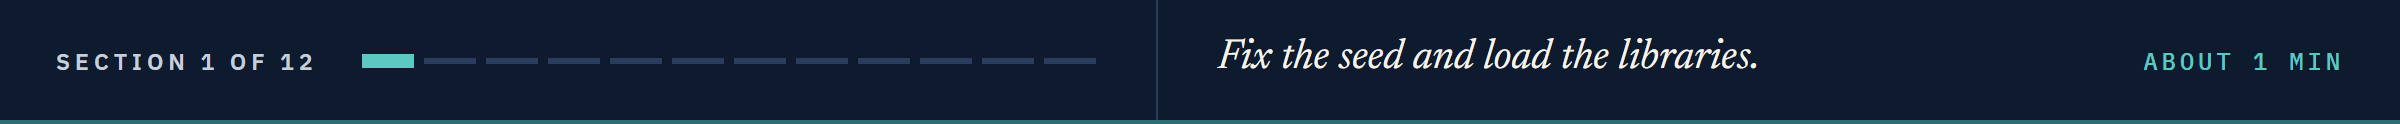

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts, and to score and choose settings by cross-validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

# the steps of a pipeline, and the models
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# to score flags and rankings
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.4f}".format)

# one colour for each of the four kinds of account a confusion matrix counts, the same on Days 7 to 10
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

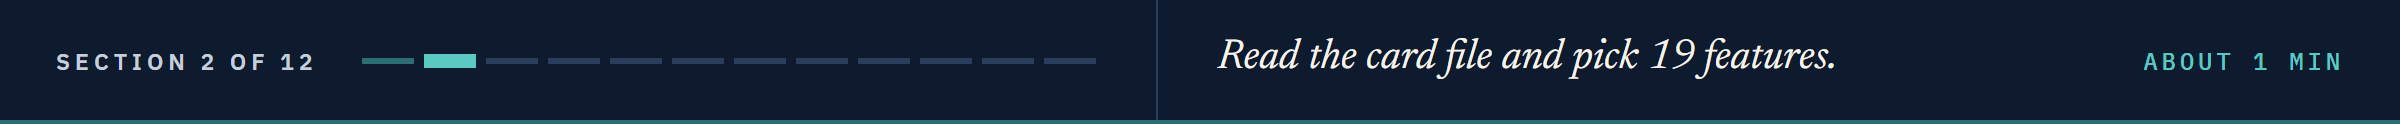

# Loading the Data

## Reading the Card File and Choosing the Features

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

# every column except the ID, the four person columns and the target
PERSON_COLUMNS = ["SEX", "EDUCATION", "MARRIAGE", "AGE"]
FEATURES = [column for column in card.columns if column not in ["ID", TARGET] + PERSON_COLUMNS]
X, y = card[FEATURES], card[TARGET]
print(len(FEATURES), "features")

19 features


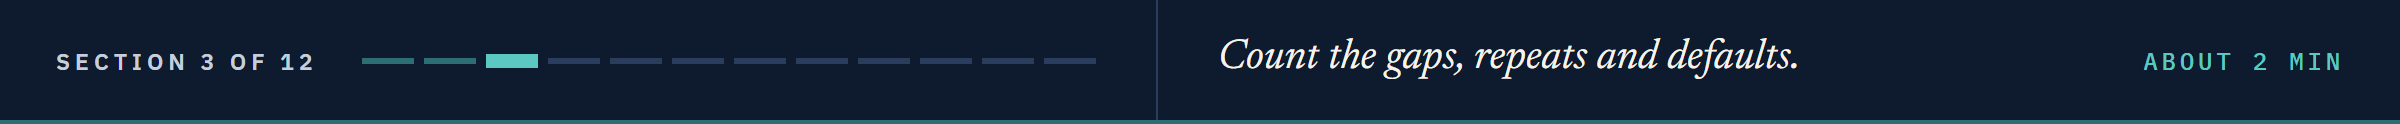

# Data Overview

## Checking the Shape, the Gaps and the Default Share

In [4]:
# rows and columns, missing values, rows that repeat another apart from the ID, and the defaults
print(card.shape)
print("Missing values:", card.isnull().sum().sum(), " Repeated rows:", card.drop(columns="ID").duplicated().sum())
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)
Missing values: 0  Repeated rows: 35
Defaults: 6636  Share: 22.12 percent


Nothing is missing, and the 35 repeated rows are different accounts under their own IDs, kept as on Day 9.

6,636 accounts defaulted, 22.12 percent.

## Checking the Statistical Summary of the Amounts

In [5]:
# accounts that paid nothing in September, and September bills below zero (a credit balance), in percent
print("Paid 0 in September:", round((card["PAY_AMT1"] == 0).mean() * 100, 1), " Bill below 0:", round((card["BILL_AMT1"] < 0).mean() * 100, 1))

# the credit limit, the September bill and the September payment, NT dollars
card[["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].describe()

Paid 0 in September: 17.5  Bill below 0: 2.0


,LIMIT_BAL,BILL_AMT1,PAY_AMT1
count,"30,000.0000","30,000.0000","30,000.0000"
mean,"167,484.3227","51,223.3309","5,663.5805"
std,"129,747.6616","73,635.8606","16,563.2804"
min,"10,000.0000","-165,580.0000",0.0000
25%,"50,000.0000","3,558.7500","1,000.0000"
50%,"140,000.0000","22,381.5000","2,100.0000"
75%,"240,000.0000","67,091.0000","5,006.0000"
max,"1,000,000.0000","964,511.0000","873,552.0000"


The September payment averages 5,663.6 NT dollars, its median is 2,100, and its largest is 873,552.

17.5 percent of accounts paid nothing in September, and 2.0 percent of September bills are below zero.

**The file is clean; the amounts are not well behaved, so the exploration looks at their shape first.**

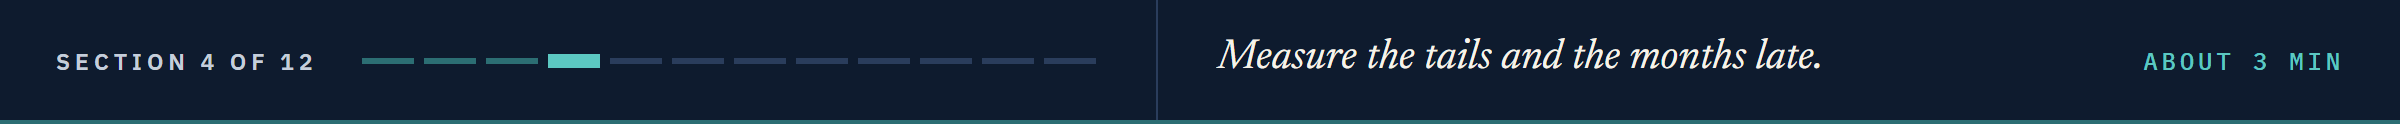

# Exploratory Data Analysis

## Univariate Analysis

### How Heavy Are the Tails?

A **letter-value plot** (`sns.boxenplot`) stacks ever thinner boxes: the middle half of the accounts, then the middle three quarters, then seven eighths, so a long tail shows as boxes instead of a cloud of dots.
A **symlog** axis is a log axis that also takes zero and negative amounts: straight near zero, then by powers of ten.

Q. How far do the twelve bill and payment columns reach?

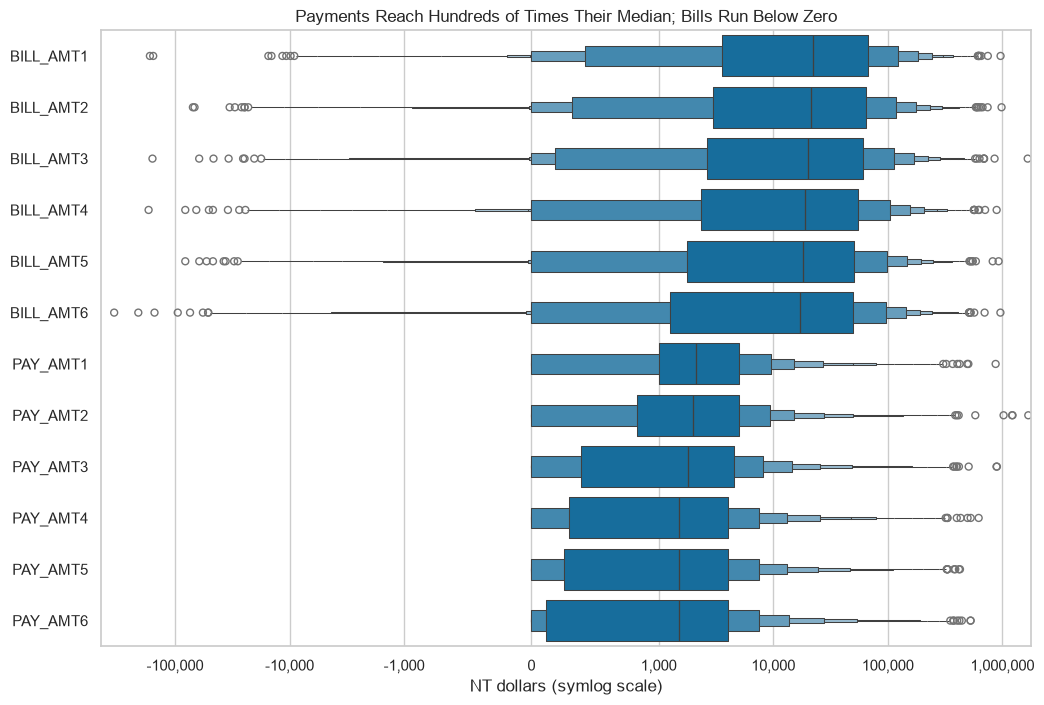

In [6]:
# the six bills and six payments, each as a letter-value plot on a symlog axis
AMOUNTS = [column for column in FEATURES if "AMT" in column]
plt.figure(figsize=(12, 8))
sns.boxenplot(data=card[AMOUNTS], orient="h", color="C0")
plt.xscale("symlog", linthresh=1000)  # linthresh: straight from -1,000 to 1,000
ticks = [-100000, -10000, -1000, 0, 1000, 10000, 100000, 1000000]
plt.xticks(ticks, [f"{tick:,}" for tick in ticks])
plt.xlabel("NT dollars (symlog scale)")
plt.title("Payments Reach Hundreds of Times Their Median; Bills Run Below Zero")
plt.show()

In [7]:
# skew of each amount (0 for a symmetric shape), and the top 1 percent of September payments
print(card[AMOUNTS + ["LIMIT_BAL"]].skew().round(2).to_dict())
print("99th percentile of PAY_AMT1:", card["PAY_AMT1"].quantile(0.99))

{'BILL_AMT1': 2.66, 'BILL_AMT2': 2.71, 'BILL_AMT3': 3.09, 'BILL_AMT4': 2.82, 'BILL_AMT5': 2.88, 'BILL_AMT6': 2.85, 'PAY_AMT1': 14.67, 'PAY_AMT2': 30.45, 'PAY_AMT3': 17.22, 'PAY_AMT4': 12.9, 'PAY_AMT5': 11.13, 'PAY_AMT6': 10.64, 'LIMIT_BAL': 0.99}
99th percentile of PAY_AMT1: 66522.17999999854


The payment columns are skewed from 10.6 to 30.5, the bills from 2.7 to 3.1, the limit only 0.99.

99 percent of September payments are at most 66,522 NT dollars, and the largest is 873,552, thirteen times that.

## Bivariate Analysis

### Default Rate by Months Late

Q. Does the default rate climb with the number of months an account was late, April to September?

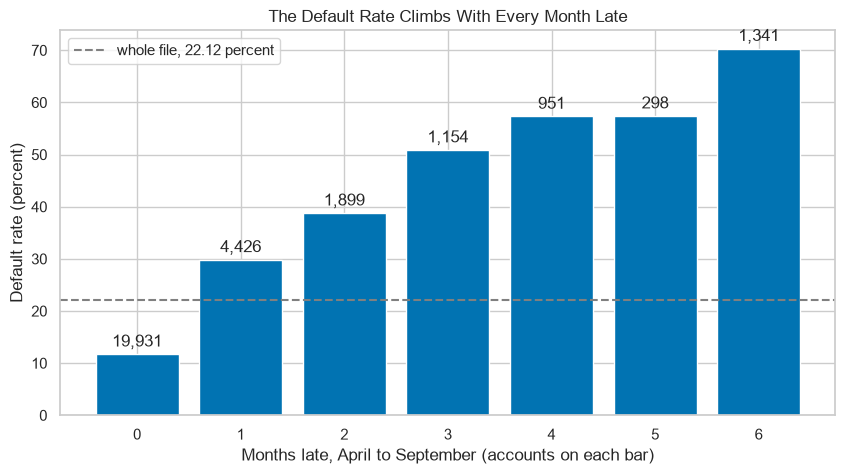

In [8]:
# for each account, how many of the six months it was one or more months late (a description, never a feature)
PAY_COLUMNS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
months_late = (card[PAY_COLUMNS] >= 1).sum(axis=1)
by_months = card.groupby(months_late)[TARGET].agg(["size", "mean"])

# the default rate for each count, the accounts written on each bar, the whole file dashed
bars = plt.bar(by_months.index, by_months["mean"] * 100)
plt.bar_label(bars, labels=[f"{n:,}" for n in by_months["size"]], padding=3)
plt.axhline(y.mean() * 100, color="gray", linestyle="--", label="whole file, 22.12 percent")
plt.xlabel("Months late, April to September (accounts on each bar)")
plt.ylabel("Default rate (percent)")
plt.title("The Default Rate Climbs With Every Month Late")
plt.legend(loc="upper left")
plt.show()

In [9]:
# the default rate at each count, in percent
(by_months["mean"] * 100).round(2).to_dict()

{0: 11.71, 1: 29.82, 2: 38.76, 3: 50.87, 4: 57.31, 5: 57.38, 6: 70.32}

19,931 accounts, two in three, were never late, and 11.71 percent of them defaulted.

The 1,341 accounts late in all six months defaulted at 70.32 percent.

The rate climbs at every step, barely from four months to five: 57.31 to 57.38.

**Status separates the outcomes most, as Days 6 and 9 found; the amounts carry theirs in long tails, so the logistic model needs them tamed and the trees do not.**

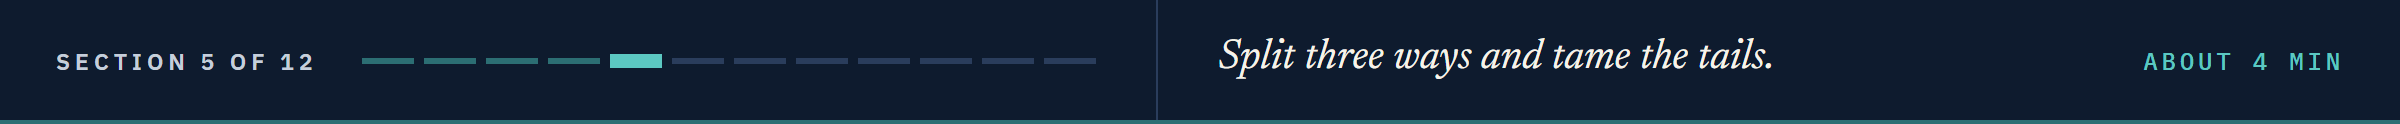

# Data Preparation for Modeling

## Splitting 60/20/20

In [10]:
# Day 6's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Default share:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Training: 18000  Validation: 6000  Test: 6000
Default share: 0.2212 0.2212 0.2212


**Training accounts fit, validation accounts choose, and the 6,000 test accounts stay closed until every choice is made.**

## Taming the Tails: the Quantile Transform

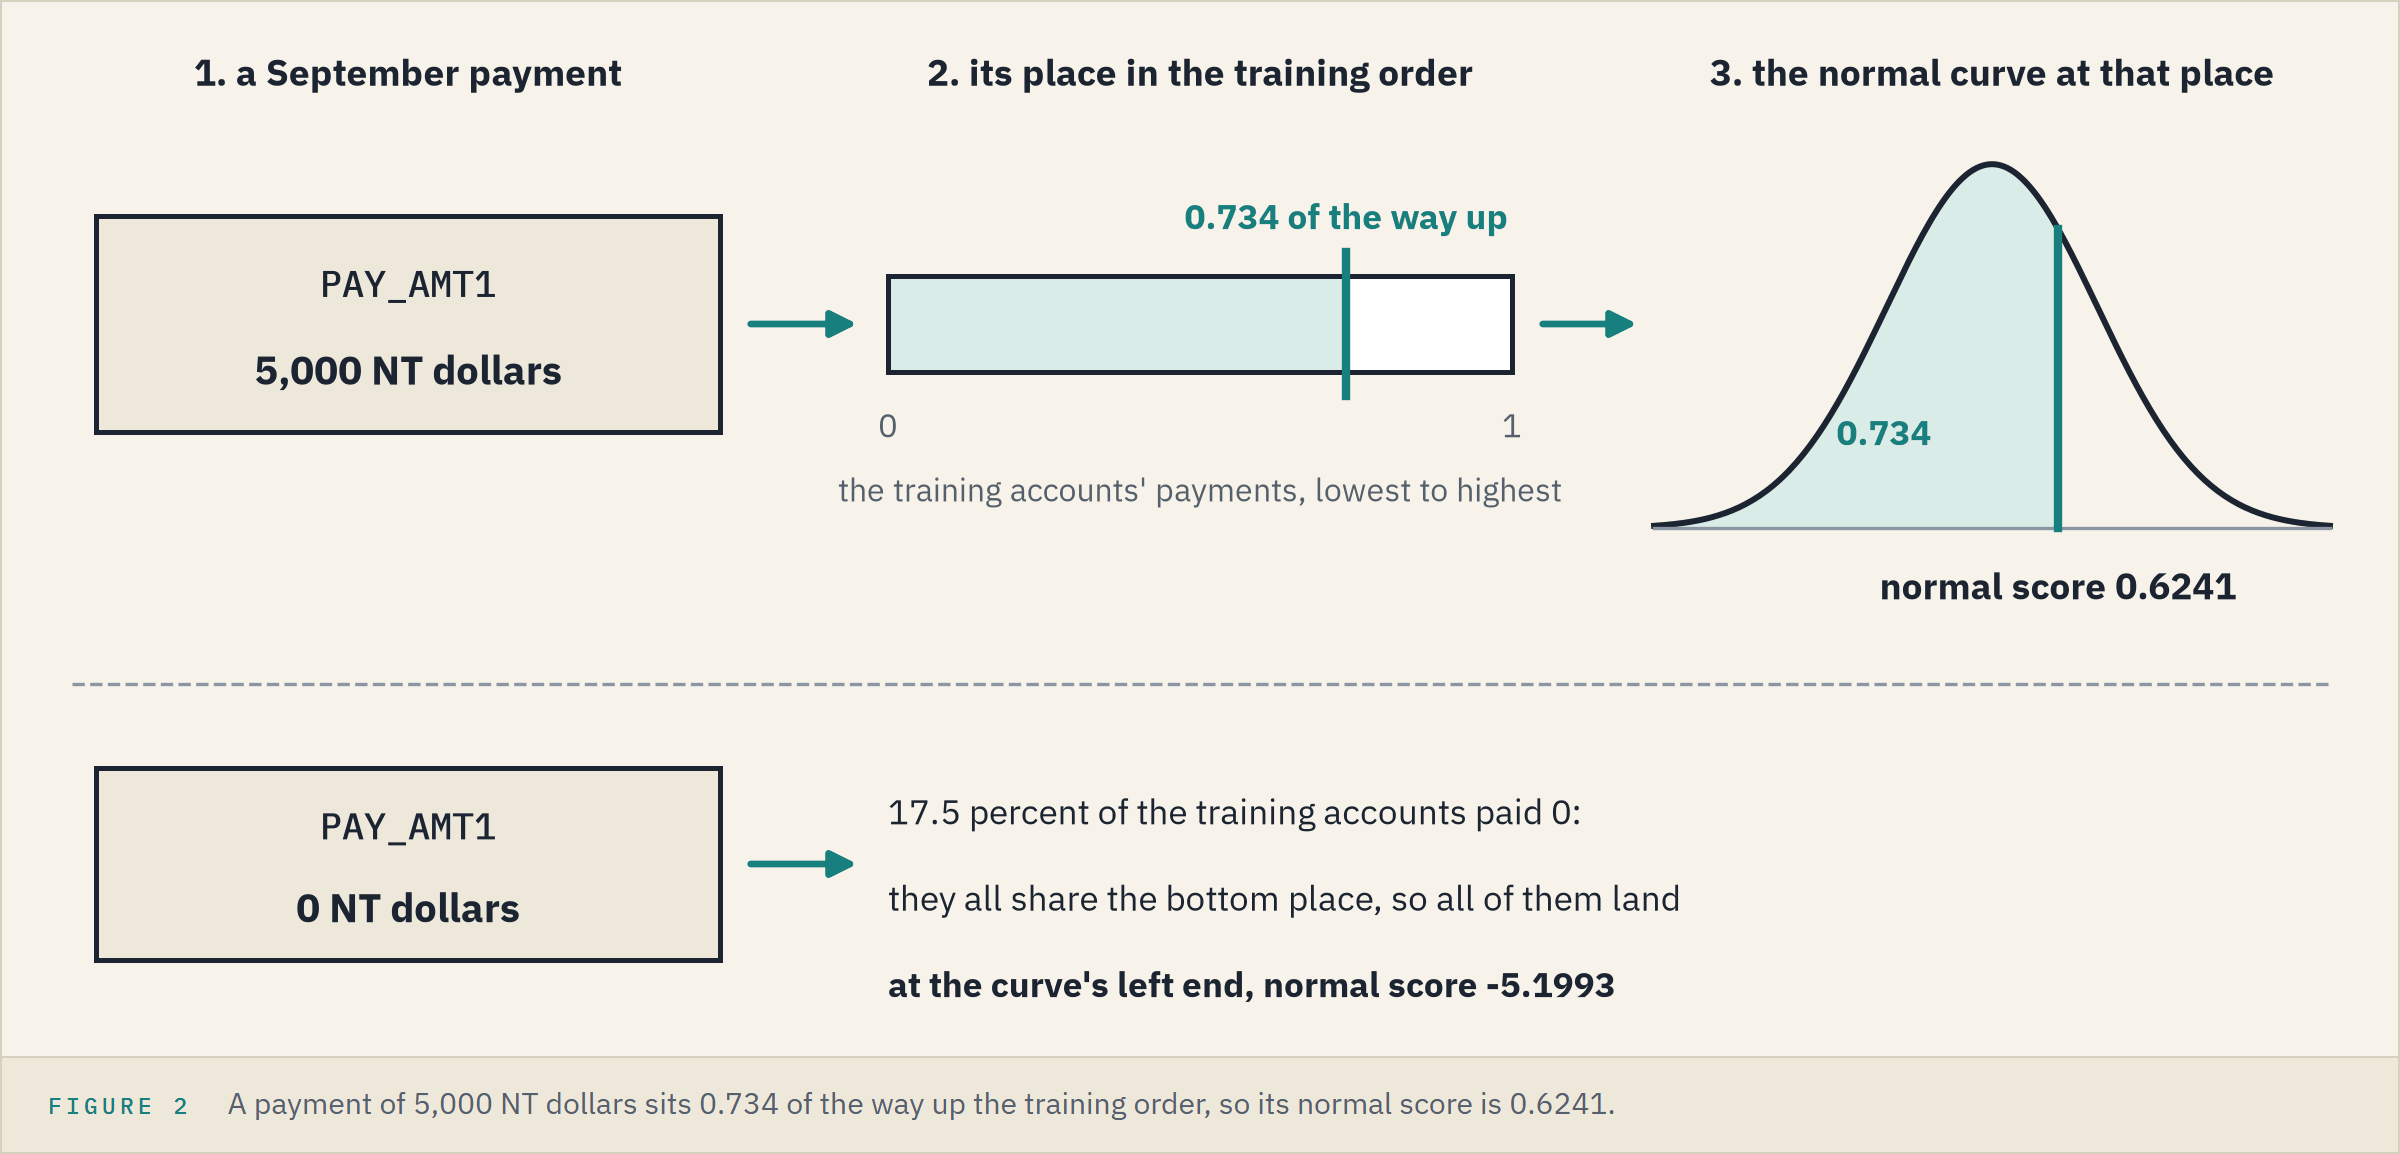

A **quantile transform** replaces each amount by its place in the training accounts' order, then by the normal curve's value at that place, a **normal score**.
`QuantileTransformer(output_distribution="normal")` learns the order from the rows it is fitted on.

In [11]:
# a demonstration: the transform alone, fitted on the training accounts' September payments
quantile = QuantileTransformer(output_distribution="normal", random_state=SEED)
pay_scores = quantile.fit_transform(X_train[["PAY_AMT1"]]).ravel()

# four payments in NT dollars, and the normal score each one gets
payments = pd.DataFrame({"PAY_AMT1": [0, 2000, 5000, 100000]})
print(quantile.transform(payments).ravel().round(4))

[-5.1993 -0.093   0.6241  2.5118]


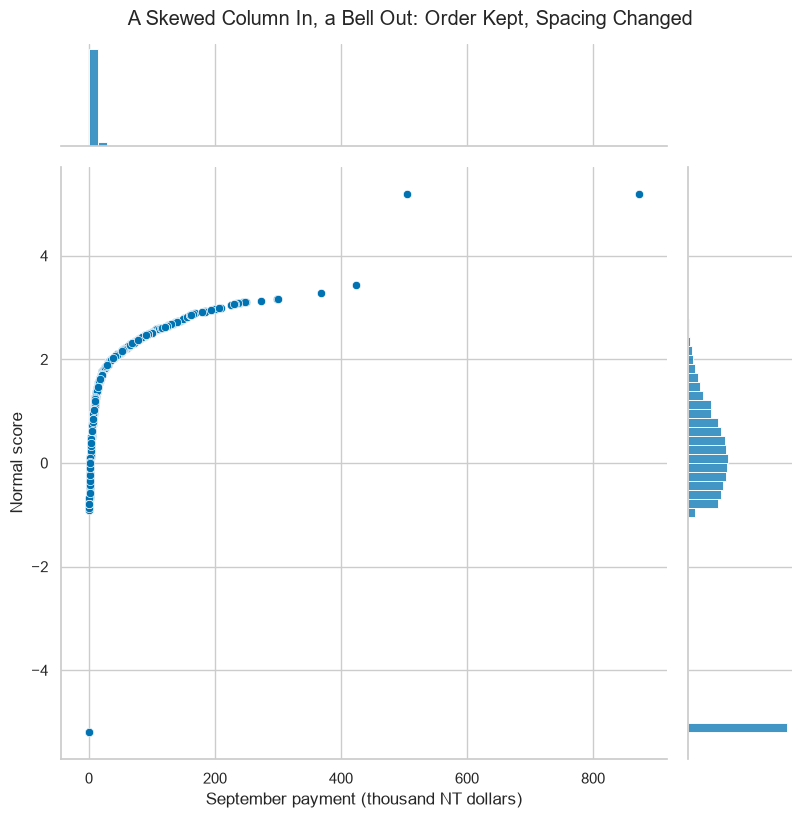

In [12]:
# each training account's payment against its normal score, both distributions on the edges
grid = sns.jointplot(x=X_train["PAY_AMT1"] / 1000, y=pay_scores, height=8, marginal_kws={"bins": 60})
grid.set_axis_labels("September payment (thousand NT dollars)", "Normal score")
grid.figure.suptitle("A Skewed Column In, a Bell Out: Order Kept, Spacing Changed", y=1.02)
plt.show()

In [13]:
# skew before and after, and the training accounts that paid 0
print("Skew before:", round(X_train["PAY_AMT1"].skew(), 2), " after:", round(pd.Series(pay_scores).skew(), 2))
print("Paid 0:", (X_train["PAY_AMT1"] == 0).sum(), "accounts, all at", round(pay_scores.min(), 4))

Skew before: 16.39  after: -1.3
Paid 0: 3157 accounts, all at -5.1993


2,000 NT dollars maps to -0.093, 5,000 to 0.6241, and 100,000 to 2.5118.

The 3,157 training accounts that paid 0 all land at -5.1993, the spike at the bell's left end.

Skew falls from 16.39 to -1.3; the order of the accounts is kept, only the spacing changes.

**The transform goes inside the pipeline, so each fold and each fit learns it from training rows only.**

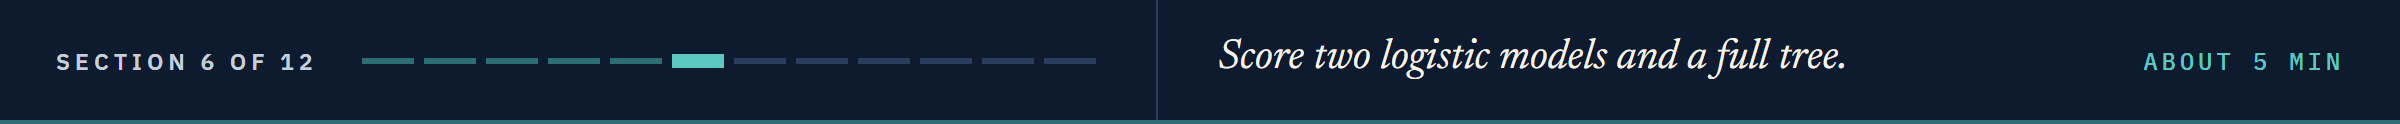

# Model Building

## Model Evaluation Criterion

A missed default and a flagged account that paid are both errors (Day 7), and no money is attached to either here.

The desk's illustration asks for a recall of 0.70: catch 70 percent of the defaults.

Models are ranked by ROC AUC on the validation accounts (Day 8), and each threshold is chosen on them by Day 8's rule.

## The Scoring Function and the Threshold Rule

Day 8's scoring function, repeated.

In [14]:
# flag at or above the threshold, then ROC AUC and four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

Day 8's rule in one line, inside a function so it serves every model: the highest threshold whose recall on the validation accounts is at least the target.

In [15]:
# every threshold's precision and recall on the validation accounts, then the highest threshold whose recall is at least the target
def threshold_for_recall(model, target_recall=0.70):
    precision, recall, thresholds = precision_recall_curve(y_valid, model.predict_proba(X_valid)[:, 1])
    return thresholds[recall[:-1] >= target_recall].max()

## Logistic Regression, Scaled

Day 6's pipeline, scored first on Day 9's five stratified folds of the training accounts with Day 5's `cross_val_score`, here by ROC AUC.

In [16]:
# Day 6's model: every column scaled, then a logistic regression
scaled_logit = Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))])

# ROC AUC on each of five folds of the training accounts, then the model fitted on all of them
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scaled_cv = cross_val_score(scaled_logit, X_train, y_train, cv=folds, scoring="roc_auc")
scaled_logit.fit(X_train, y_train)
proba_scaled = scaled_logit.predict_proba(X_valid)[:, 1]
print("Cross-validated ROC AUC:", round(scaled_cv.mean(), 4))
print("Validation ROC AUC:", round(roc_auc_score(y_valid, proba_scaled), 4), " Average precision:", round(average_precision_score(y_valid, proba_scaled), 4))

Cross-validated ROC AUC: 0.7277
Validation ROC AUC: 0.719  Average precision: 0.4946


0.7190 on the validation accounts and an average precision of 0.4946: Day 8's numbers, from the same model on the same accounts.

## Logistic Regression With the Quantile Transform

**Predict 1**

The same pipeline with the quantile transform in place of the scaler.

Q. Its validation ROC AUC rises. Write down its average precision, against 0.4946.

In [17]:
# the same model with every column given its normal score first
quantile_logit = Pipeline([("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                           ("logit", LogisticRegression(max_iter=1000))])
quantile_cv = cross_val_score(quantile_logit, X_train, y_train, cv=folds, scoring="roc_auc")
quantile_logit.fit(X_train, y_train)
proba_quantile = quantile_logit.predict_proba(X_valid)[:, 1]
print("Cross-validated ROC AUC:", round(quantile_cv.mean(), 4))
print("Validation ROC AUC:", round(roc_auc_score(y_valid, proba_quantile), 4), " Average precision:", round(average_precision_score(y_valid, proba_quantile), 4))

Cross-validated ROC AUC: 0.7366
Validation ROC AUC: 0.7291  Average precision: 0.4594


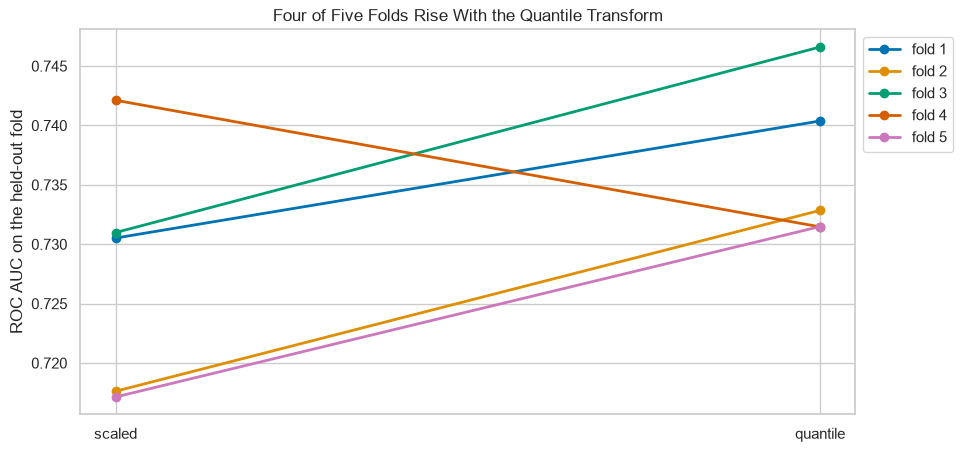

In [18]:
# fold by fold: each fold's ROC AUC with the scaler and with the quantile transform
for fold in range(5):
    plt.plot(["scaled", "quantile"], [scaled_cv[fold], quantile_cv[fold]], marker="o", linewidth=2, label=f"fold {fold + 1}")
plt.ylabel("ROC AUC on the held-out fold")
plt.title("Four of Five Folds Rise With the Quantile Transform")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

ROC AUC rises, 0.7277 to 0.7366 across the folds and 0.7190 to 0.7291 on validation, and four of the five folds rise.

Average precision falls, 0.4946 to 0.4594: the two scores read the ranking in different places.

**ROC AUC is the criterion, so the quantile pipeline goes forward; the gains chart below shows where the average precision went.**

## Decision Tree With Balanced Weights

In [19]:
# Day 9's tree with balanced weights and no limits, on the training and validation accounts at 0.5
full_tree = DecisionTreeClassifier(class_weight="balanced", random_state=SEED).fit(X_train, y_train)
print("Depth:", full_tree.get_depth(), " Leaves:", full_tree.get_n_leaves())
full_perf = pd.concat([model_performance_classification(full_tree, X_train, y_train).T,
                       model_performance_classification(full_tree, X_valid, y_valid).T], axis=1)
full_perf.columns = ["training", "validation"]
full_perf

Depth: 49  Leaves: 3233


,training,validation
ROC AUC,0.9997,0.6158
Accuracy,0.9866,0.7262
Recall,0.9997,0.4160
Precision,0.9431,0.3887
F1,0.9706,0.4019


ROC AUC 0.9997 on the training accounts and 0.6158 on validation: Day 9's full balanced tree, a memoriser again.

**So the tree is pruned.**

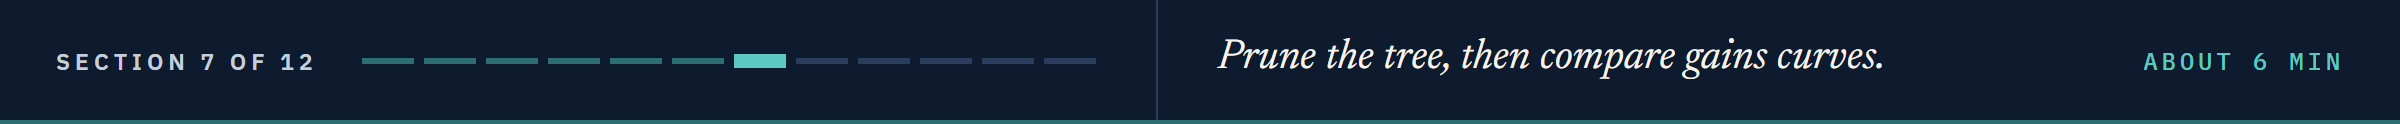

# Model Performance Improvement

## Pruning the Tree by Cross-Validation

In [20]:
# Day 9's search over ccp_alpha, its five largest alphas, scored by ROC AUC on the same five folds
alphas = [0.0002, 0.0005, 0.001, 0.002, 0.005]
search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=SEED), {"ccp_alpha": alphas},
                      cv=folds, scoring="roc_auc")
search.fit(X_train, y_train)
pruned_tree = search.best_estimator_
print(pd.Series(search.cv_results_["mean_test_score"], index=alphas).round(4).to_dict())
print(search.best_params_, " Depth:", pruned_tree.get_depth(), " Leaves:", pruned_tree.get_n_leaves())

{0.0002: 0.6838, 0.0005: 0.7589, 0.001: 0.7598, 0.002: 0.7496, 0.005: 0.7369}
{'ccp_alpha': 0.001}  Depth: 6  Leaves: 12


0.001 scores best inside the grid, 0.7598, with smaller and larger alphas on both sides.

12 leaves, 6 questions deep: Day 9's post-pruned tree, the same settings and the same tree.

## Thresholds for a Recall of 0.70

**Predict 2**

At 0.5 the default tree catches 41.6 percent of the validation defaults.

Q. How many of the 6,000 validation accounts must it flag to catch 70 percent?

In [21]:
# the four models by name, each with one colour for every chart below
models = {"scaled logistic": scaled_logit, "quantile logistic": quantile_logit, "pruned tree": pruned_tree, "default tree": full_tree}
COLOURS = {"scaled logistic": "C7", "quantile logistic": "C0", "pruned tree": "C2", "default tree": "C4"}

# each model's threshold for a recall of 0.70, and the validation accounts it flags
thresholds_70 = {name: threshold_for_recall(model) for name, model in models.items()}
flagged_70 = {name: (model.predict_proba(X_valid)[:, 1] >= thresholds_70[name]).sum() for name, model in models.items()}
pd.DataFrame({"threshold": thresholds_70, "flagged": flagged_70})

,threshold,flagged
scaled logistic,0.2025,2843
quantile logistic,0.2011,2506
pruned tree,0.4608,2382
default tree,0.0000,6000


In [22]:
# the default tree's outputs on the validation accounts: the share at exactly 0 and at exactly 1
full_valid = full_tree.predict_proba(X_valid)[:, 1]
print("At 0:", round((full_valid == 0).mean(), 3), " At 1:", round((full_valid == 1).mean(), 3))

At 0: 0.763  At 1: 0.213


76.3 percent of the default tree's validation outputs are exactly 0 and 21.3 percent exactly 1.

The outputs above 0 catch too few defaults, so the only threshold that reaches 0.70 is 0, and it flags all 6,000 accounts.

## Gains on the Validation Accounts

A **cumulative gains curve** sorts the accounts by the model's output, highest first, and walks down the list.
Across: the share of accounts flagged so far; up: the share of the defaults caught.
At each threshold `roc_curve` gives the share of the defaults caught and the share of the paid accounts flagged.
Times their counts, the two add up to the accounts flagged.

Q. To catch 70 percent of the defaults, what share of the accounts does each model flag?

In [23]:
# a model's gains curve on the validation accounts in percent, and its flags at the threshold for the target
def gains(model, target):
    output = model.predict_proba(X_valid)[:, 1]
    fpr, tpr, _ = roc_curve(y_valid, output)
    flagged_share = (tpr * y_valid.sum() + fpr * (y_valid == 0).sum()) / len(y_valid)
    return flagged_share * 100, tpr * 100, output >= threshold_for_recall(model, target)

In [24]:
# the four curves, each with a dot where its threshold for the target lands; the key gives that threshold's flags and precision
def draw_gains(target=0.70):
    plt.figure(figsize=(11, 8))
    for name, model in models.items():
        flagged_share, caught, flags = gains(model, target)
        key = f"{name}: {flags.mean():.1%} flagged, precision {precision_score(y_valid, flags):.4f}"
        plt.plot(flagged_share, caught, linewidth=2.5, color=COLOURS[name], label=key)
        plt.scatter(flags.mean() * 100, recall_score(y_valid, flags) * 100, s=160, color=COLOURS[name], zorder=3)
    plt.plot([0, 100], [0, 100], color="gray", linestyle="--", label="accounts in random order")
    plt.plot([0, y_valid.mean() * 100, 100], [0, 100, 100], color="black", linestyle=":", label="a perfect order")
    plt.axhline(target * 100, color="gray", linewidth=0.8)
    plt.xlabel("Validation accounts flagged (percent)")
    plt.ylabel("Defaults caught (percent)")
    plt.title(f"Recall Target {target:.0%}: the Curves Cross, So the Model That Flags Fewest Depends on the Target")
    plt.legend(loc="lower right")
    plt.show()

### Your Turn: Move the Recall Target

Slide the target from 0.50 to 0.90 and watch each dot ride its curve.

In [25]:
# your turn: one slider for the recall target
interact(draw_gains, target=(0.50, 0.90, 0.05));

interactive(children=(FloatSlider(value=0.7, description='target', max=0.9, min=0.5, step=0.05), Output()), _d…

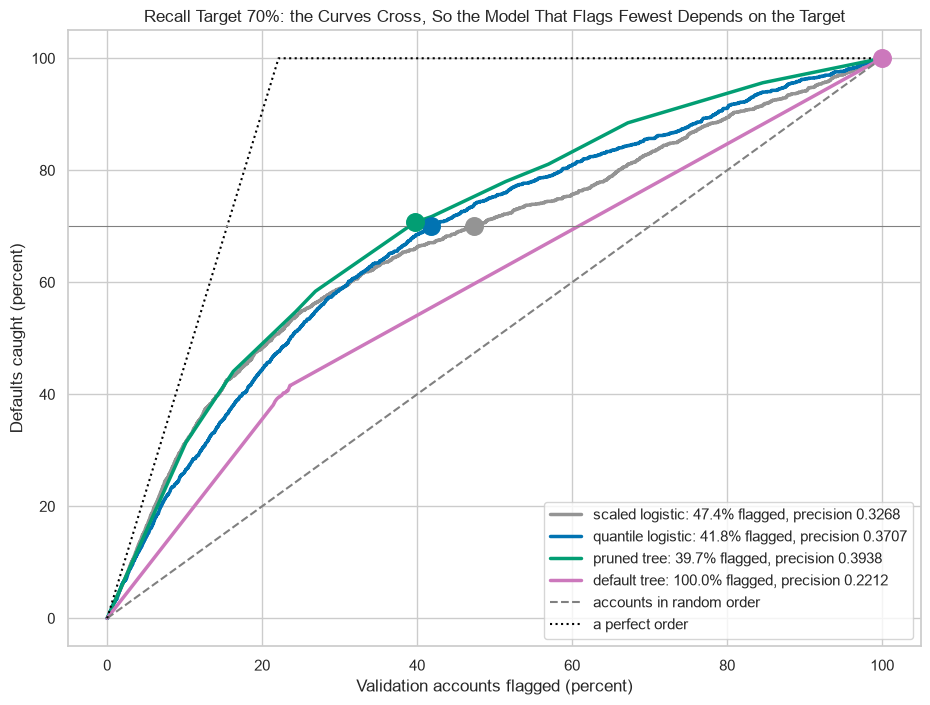

In [26]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_gains(target=0.70)

In [27]:
# the share of the defaults each logistic model catches in its top tenth of validation accounts
for name, proba in [("scaled logistic", proba_scaled), ("quantile logistic", proba_quantile)]:
    top_tenth = proba >= np.quantile(proba, 0.9)  # np.quantile: the value 90 percent of the way up
    print(name, round(y_valid[top_tenth].sum() / y_valid.sum() * 100, 1), "percent of the defaults")

scaled logistic 31.1 percent of the defaults
quantile logistic 26.1 percent of the defaults


To catch 70 percent of the defaults the pruned tree flags 39.7 percent of the accounts, the quantile logistic 41.8, the scaled logistic 47.4, the default tree all of them.

The tree's curve climbs one leaf at a time, so the curves cross: slide the target and the model that flags fewest changes.

In its top tenth the scaled logistic catches 31.1 percent of the defaults against 26.1 for the quantile one: its higher average precision lives at the top of the list, and the quantile one catches up further down.

**The curve that reaches 70 percent first flags the fewest accounts that paid.**

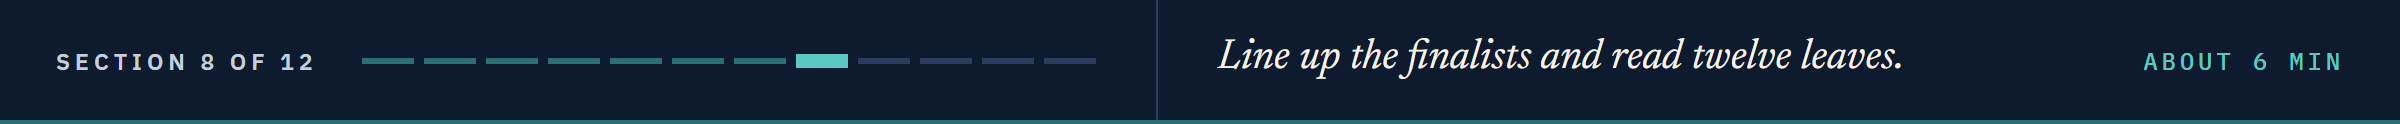

# Final Model Selection

## Validation Performance

The default tree stays at 0.5 in the tables: at its 0.70 threshold it flags every account.

In [28]:
# the three finalists on the validation accounts: each at its threshold for 0.70, the default tree at 0.5
finalists = {"quantile logistic": thresholds_70["quantile logistic"], "default tree": 0.5, "pruned tree": thresholds_70["pruned tree"]}
valid_comp = pd.concat([model_performance_classification(models[name], X_valid, y_valid, t).T for name, t in finalists.items()], axis=1)
valid_comp.columns = list(finalists)
valid_comp

,quantile logistic,default tree,pruned tree
ROC AUC,0.7291,0.6158,0.7627
Accuracy,0.6708,0.7262,0.6945
Recall,0.7001,0.4160,0.7069
Precision,0.3707,0.3887,0.3938
F1,0.4847,0.4019,0.5058


The pruned tree leads on ROC AUC, 0.7627 against 0.7291, and at recall 0.7069 its precision is 0.3938 against the logistic's 0.3707.

## How Each Model Scores the Accounts

Q. What do the outputs of the four models look like, for the accounts that paid and those that defaulted?

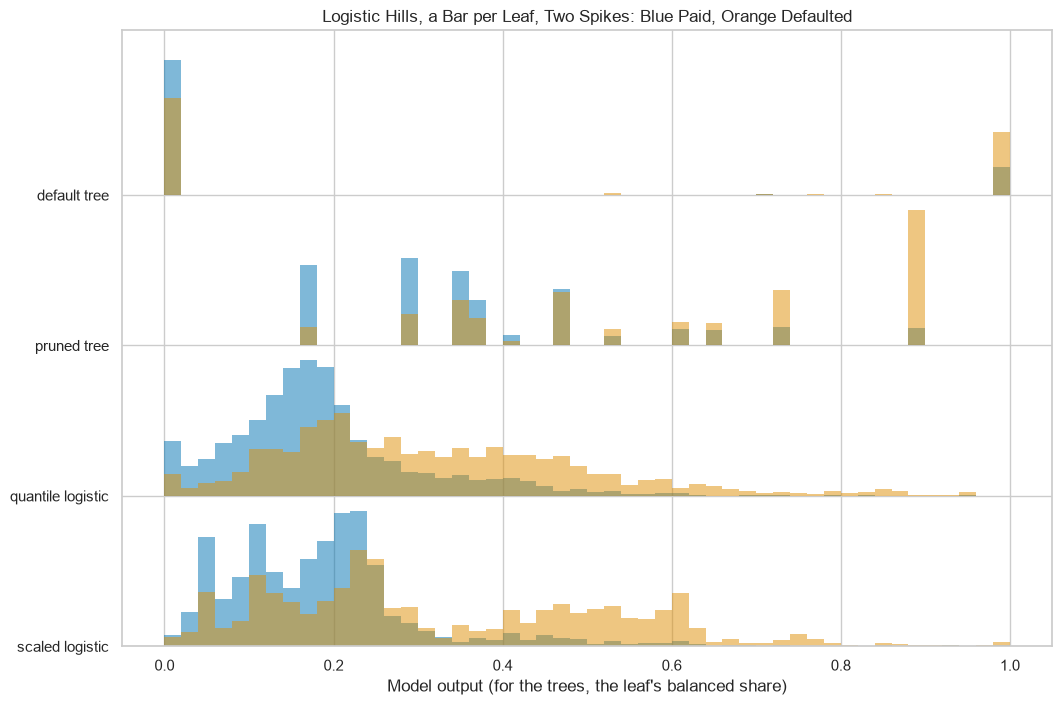

In [29]:
# a ridgeline: one row per model, the share of each outcome's validation accounts in each band of 0.02, scaled to the row's tallest band
bands = np.linspace(0, 1, 51)
plt.figure(figsize=(12, 8))
for row, (name, model) in enumerate(models.items()):
    output = model.predict_proba(X_valid)[:, 1]
    # np.histogram counts the outputs in each band; dividing by the outcome's accounts makes shares
    shares = [np.histogram(output[y_valid == outcome], bins=bands)[0] / (y_valid == outcome).sum() for outcome in (0, 1)]
    tallest = max(shares[0].max(), shares[1].max())
    for share, colour in zip(shares, ["C0", "C1"]):
        plt.stairs(row + 0.9 * share / tallest, bands, baseline=row, fill=True, color=colour, alpha=0.5)  # stairs: bars from heights already counted
plt.yticks(range(len(models)), list(models))
plt.xlabel("Model output (for the trees, the leaf's balanced share)")
plt.title("Logistic Hills, a Bar per Leaf, Two Spikes: Blue Paid, Orange Defaulted")
plt.show()

A **ridgeline** stacks one distribution per row; within a row each colour's shares add to one, so the two outcomes compare as shapes.

The logistic models spread their outputs in hills, and the default tree puts nearly all of its at 0 and at 1.

The pruned tree gives one bar per leaf, with two of its twelve leaves inside one band.

## Two Scores Side by Side

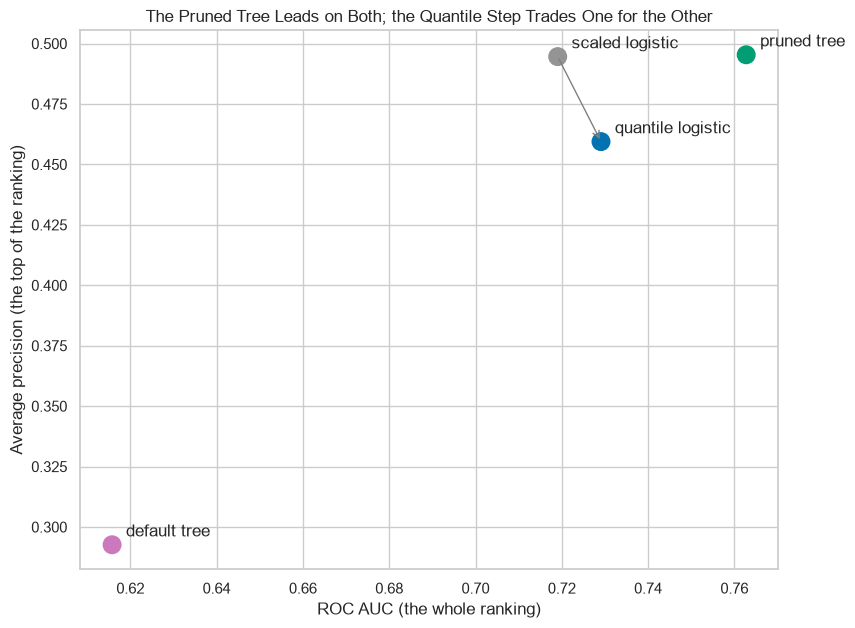

In [30]:
# ROC AUC and average precision of the four models on the validation accounts
scores = pd.DataFrame({name: [roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1]), average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])]
                       for name, m in models.items()}, index=["ROC AUC", "average precision"]).T

# each model as a point, an arrow from the scaled logistic to the quantile one
plt.figure(figsize=(9, 7))
plt.scatter(scores["ROC AUC"], scores["average precision"], s=160, color=[COLOURS[name] for name in scores.index])
for name, row in scores.iterrows():
    # textcoords="offset points": xytext is a shift from the dot in points, not in data units
    plt.annotate(name, (row["ROC AUC"], row["average precision"]), xytext=(10, 6), textcoords="offset points")
plt.annotate("", xy=scores.loc["quantile logistic"], xytext=scores.loc["scaled logistic"], arrowprops={"arrowstyle": "->", "color": "gray"})
plt.xlabel("ROC AUC (the whole ranking)")
plt.ylabel("Average precision (the top of the ranking)")
plt.title("The Pruned Tree Leads on Both; the Quantile Step Trades One for the Other")
plt.show()

A **metric map** puts two scores on two axes, so a model up and to the right is better on both.

The pruned tree is highest on both; the arrow shows the quantile step buying ROC AUC with average precision.

## Where the Two Good Models Agree

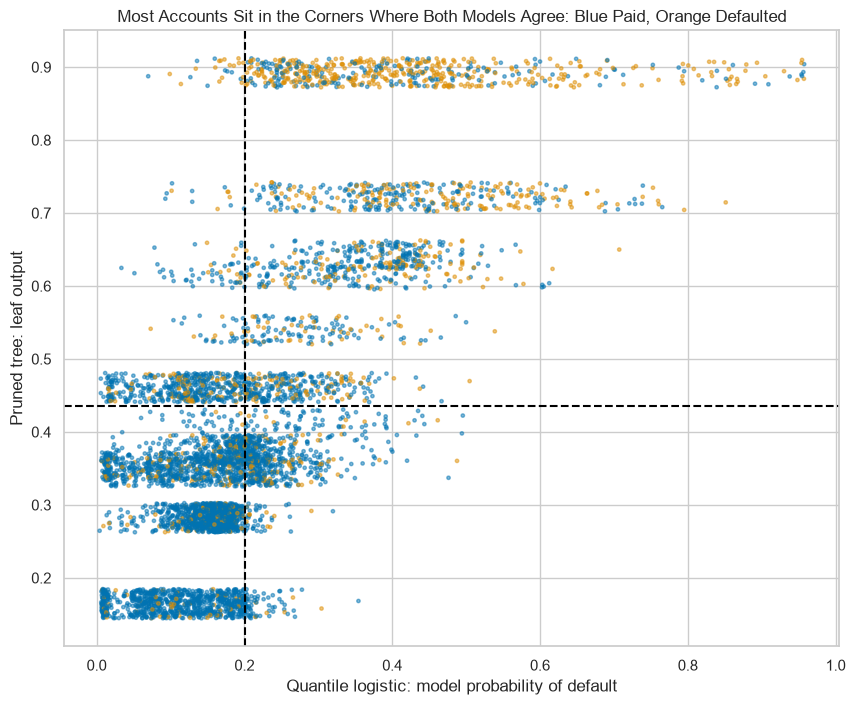

In [31]:
# the logistic's output against the tree's, the tree's twelve values spread a little so the dots show (seeded)
tree_valid = pruned_tree.predict_proba(X_valid)[:, 1]
spread = np.random.default_rng(SEED).uniform(-0.02, 0.02, len(tree_valid))
plt.figure(figsize=(10, 8))
plt.scatter(proba_quantile, tree_valid + spread, c=y_valid.map({0: "C0", 1: "C1"}), s=6, alpha=0.5)
plt.axvline(thresholds_70["quantile logistic"], color="black", linestyle="--")
plt.axhline(thresholds_70["pruned tree"] - 0.025, color="black", linestyle="--")  # just under the spread of the lowest flagged leaf
plt.xlabel("Quantile logistic: model probability of default")
plt.ylabel("Pruned tree: leaf output")
plt.title("Most Accounts Sit in the Corners Where Both Models Agree: Blue Paid, Orange Defaulted")
plt.show()

In [32]:
# the four quadrants: accounts flagged by both, by one, by neither, and how many of each defaulted
logit_flag = proba_quantile >= thresholds_70["quantile logistic"]
tree_flag = tree_valid >= thresholds_70["pruned tree"]
quadrants = pd.DataFrame({"logistic": logit_flag, "tree": tree_flag, "defaulted": y_valid.values})
print(quadrants.groupby(["logistic", "tree"])["defaulted"].agg(["size", "sum"]))
print("Same flag:", (logit_flag == tree_flag).sum(), " Correlation:", round(pd.Series(proba_quantile).corr(pd.Series(tree_valid)), 2))

                size  sum
logistic tree            
False    False  2893  270
         True    601  128
True     False   725  119
         True   1781  810
Same flag: 4674  Correlation: 0.71


A **quadrant chart** cuts a scatter at each model's threshold.

The two models give the same flag to 4,674 of 6,000 accounts; both flag 1,781, of which 810 defaulted; neither flags 2,893, of which 270 defaulted.

Their outputs correlate at 0.71.

## The Chosen Model: Twelve Leaves

`.apply` gives the leaf each account lands in.

In [33]:
# each training account's leaf, then each leaf's accounts, default share and output
leaf_rows = pd.DataFrame({"leaf": pruned_tree.apply(X_train), "defaulted": y_train.values,
                          "output": pruned_tree.predict_proba(X_train)[:, 1]})
leaves = leaf_rows.groupby("leaf").agg(accounts=("defaulted", "size"), default_share=("defaulted", "mean"),
                                       output=("output", "first")).sort_values("default_share", ascending=False)
leaves["flagged"] = leaves["output"] >= thresholds_70["pruned tree"]
leaves

,accounts,default_share,output,flagged
leaf,,,,
22,1885,0.7013,0.8921,True
21,1102,0.4247,0.7221,True
19,689,0.3382,0.6427,True
6,699,0.3119,0.6147,True
15,504,0.2500,0.5399,True
4,2416,0.1954,0.4608,True
20,478,0.1653,0.4107,False
9,1666,0.1459,0.3755,False
11,950,0.1337,0.3520,False


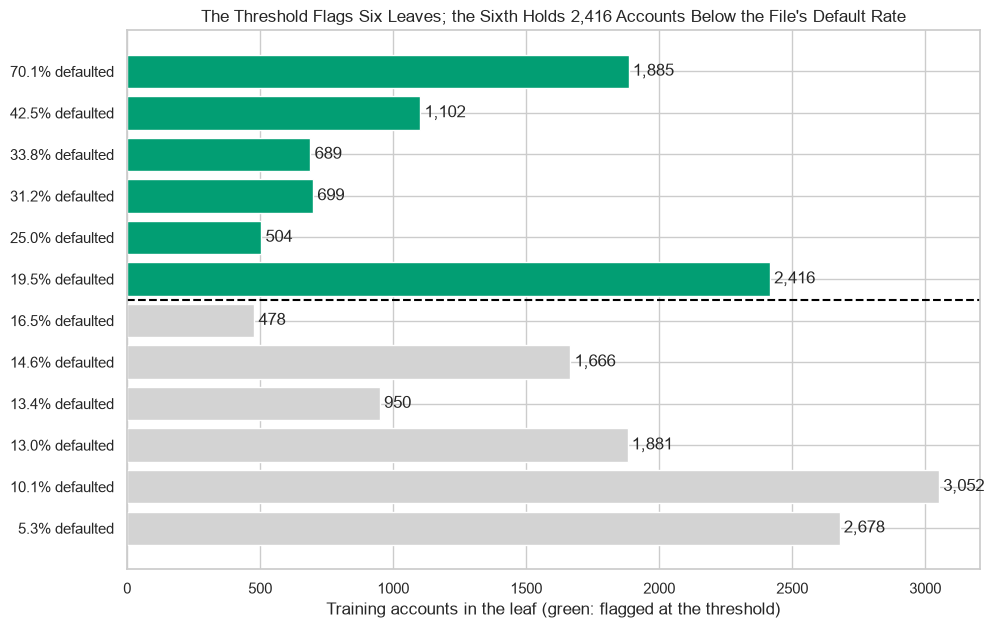

In [34]:
# a leaf ladder: one bar per leaf, highest default share first, as long as its training accounts; flagged leaves in the tree's colour
labels = [f"{share:.1%} defaulted" for share in leaves["default_share"]]
colours = [COLOURS["pruned tree"] if flagged else "lightgray" for flagged in leaves["flagged"]]
plt.figure(figsize=(11, 7))
bars = plt.barh(labels, leaves["accounts"], color=colours)
plt.bar_label(bars, labels=[f"{n:,}" for n in leaves["accounts"]], padding=3)
plt.gca().invert_yaxis()  # highest default share at the top
plt.axhline(5.5, color="black", linestyle="--")
plt.xlabel("Training accounts in the leaf (green: flagged at the threshold)")
plt.title("The Threshold Flags Six Leaves; the Sixth Holds 2,416 Accounts Below the File's Default Rate")
plt.show()

The top leaf, September status 2 or more in Day 9's rules, holds 1,885 training accounts at 70.1 percent.

The threshold flags six leaves, 7,295 training accounts.

The last flagged leaf holds 2,416 accounts at 19.5 percent, below the file's 22.1: reaching 0.70 costs a leaf of mostly paying accounts.

**The pruned tree goes forward: the highest validation ROC AUC, the fewest flags for the recall asked, and twelve rules a reader can check.**

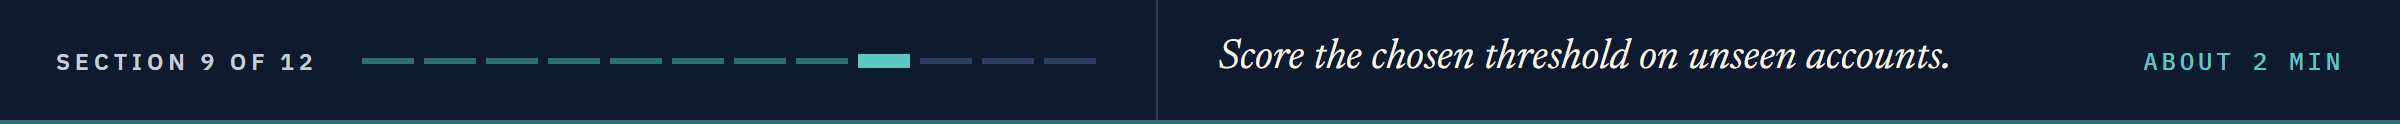

# The Test Rows, Opened Once

**Predict 3**

On the validation accounts the pruned tree's threshold catches 70.69 percent of the defaults.

Q. Write down its recall on the 6,000 test accounts.

In [35]:
# the test accounts, opened once: each finalist at the threshold chosen on the validation accounts
test_comp = pd.concat([model_performance_classification(models[name], X_test, y_test, t).T for name, t in finalists.items()], axis=1)
test_comp.columns = list(finalists)
test_comp

,quantile logistic,default tree,pruned tree
ROC AUC,0.7214,0.6128,0.7544
Accuracy,0.6575,0.7275,0.6810
Recall,0.6858,0.4084,0.6993
Precision,0.3571,0.3894,0.3799
F1,0.4697,0.3987,0.4923


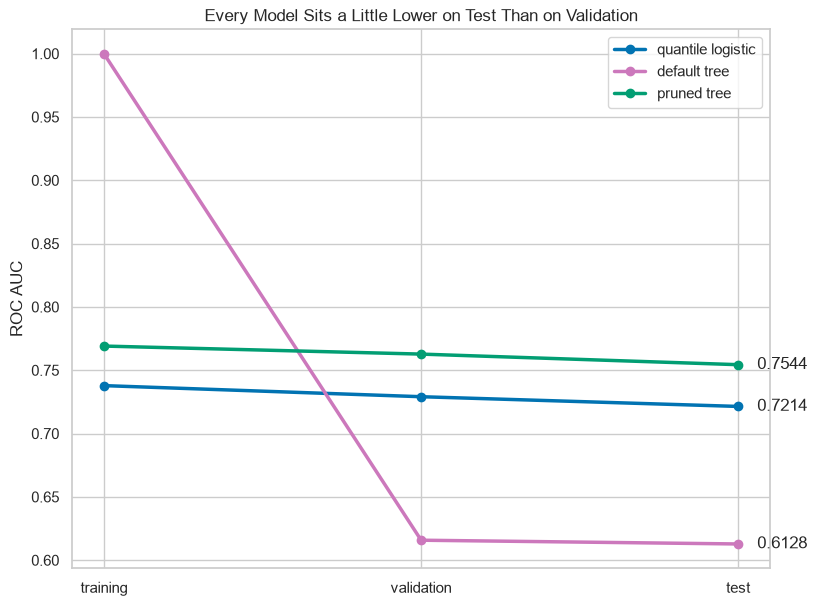

In [36]:
# ROC AUC on training, validation and test accounts, one line per finalist
splits = {"training": (X_train, y_train), "validation": (X_valid, y_valid), "test": (X_test, y_test)}
plt.figure(figsize=(9, 7))
for name in finalists:
    auc_by_split = [roc_auc_score(target, models[name].predict_proba(rows)[:, 1]) for rows, target in splits.values()]
    plt.plot(list(splits), auc_by_split, marker="o", linewidth=2.5, color=COLOURS[name], label=name)
    plt.text(2.06, auc_by_split[2], f"{auc_by_split[2]:.4f}", va="center")
plt.ylabel("ROC AUC")
plt.title("Every Model Sits a Little Lower on Test Than on Validation")
plt.legend(loc="upper right")
plt.show()

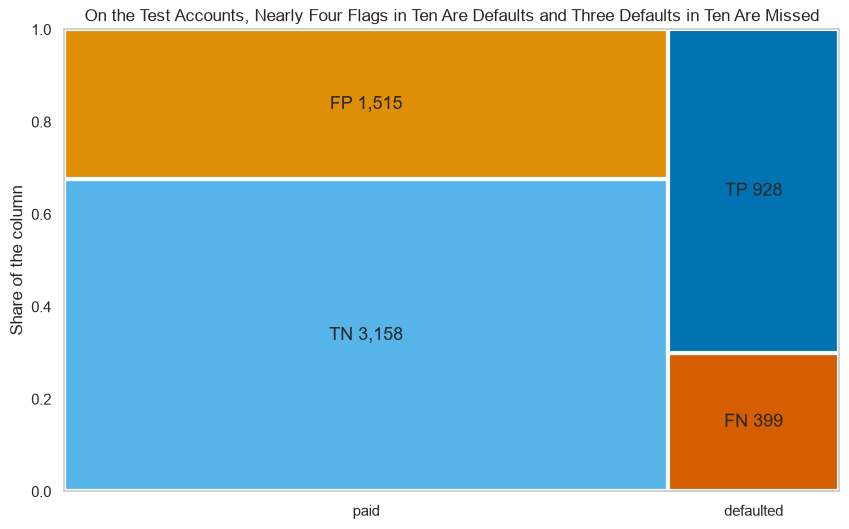

In [37]:
# the pruned tree's test matrix drawn to scale, as on Day 7: each outcome a column as wide as its share
test_flags = (pruned_tree.predict_proba(X_test)[:, 1] >= thresholds_70["pruned tree"]).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_flags).ravel()
widths = [(tn + fp) / len(y_test), (fn + tp) / len(y_test)]
lower = [tn / (tn + fp), fn / (fn + tp)]
fig, ax = plt.subplots(figsize=(10, 6))
bottom = ax.bar([0, widths[0]], lower, width=widths, align="edge", color=[CELL_COLOURS["TN"], CELL_COLOURS["FN"]], edgecolor="white", linewidth=3)
top = ax.bar([0, widths[0]], [1 - lower[0], 1 - lower[1]], bottom=lower, width=widths, align="edge", color=[CELL_COLOURS["FP"], CELL_COLOURS["TP"]], edgecolor="white", linewidth=3)
ax.bar_label(bottom, labels=[f"TN {tn:,}", f"FN {fn:,}"], label_type="center", fontsize=13)
ax.bar_label(top, labels=[f"FP {fp:,}", f"TP {tp:,}"], label_type="center", fontsize=13)
ax.set(xlim=(0, 1), ylim=(0, 1), xticks=[widths[0] / 2, widths[0] + widths[1] / 2], xticklabels=["paid", "defaulted"], ylabel="Share of the column")
ax.set_title("On the Test Accounts, Nearly Four Flags in Ten Are Defaults and Three Defaults in Ten Are Missed")
plt.show()

Every model scores a little lower on the test accounts than on validation, and lower again than on training.

Recall 0.6993 against 0.7069 on validation: a threshold fitted to one set of defaults carries its noise to new ones.

928 defaults caught and 399 missed; 1,515 of the 4,673 paid accounts flagged.

**The numbers held on accounts nobody chose with.**

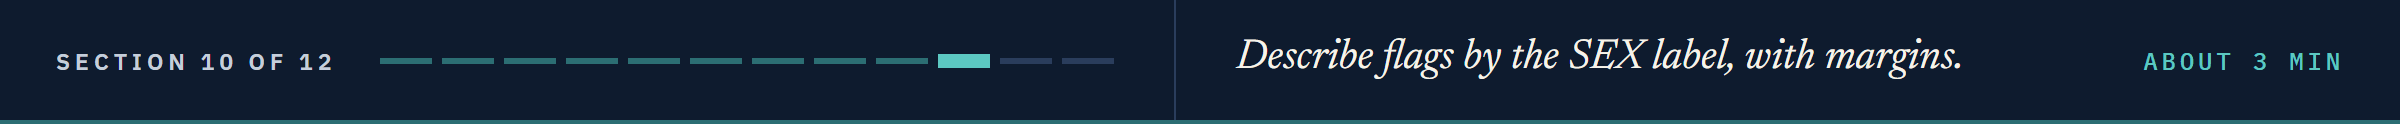

# The Person Columns

## Do They Add Anything?

**Predict 4**

Q. Add the four person columns to the quantile logistic. By how much does its cross-validated ROC AUC change?

In [38]:
# the quantile logistic, cross-validated on the same folds without and with the four person columns
with_person = card.loc[X_train.index, FEATURES + PERSON_COLUMNS]
print("Without:", round(quantile_cv.mean(), 4))
print("With:", round(cross_val_score(quantile_logit, with_person, y_train, cv=folds, scoring="roc_auc").mean(), 4))

Without: 0.7366
With: 0.7368


0.7366 to 0.7368: the four columns add almost nothing to the ranking, and the case study's models never use them.

Leaving them out keeps them out of every model's questions.

It does not stop other columns from carrying the same information, and nothing here measures how much they do.

## Flags by the SEX Label

The file codes `SEX` as 1 and 2, labelled male and female in its own description.

Q. Does the pruned tree flag the two labels at different rates on the test accounts, and catch their defaults at different rates?

In [39]:
# the test flags beside each account's label, then each label's flag rate and recall
test_rows = pd.DataFrame({"label": card.loc[X_test.index, "SEX"].map({1: "male", 2: "female"}), "defaulted": y_test, "flagged": test_flags})
by_label = test_rows.groupby("label").agg(accounts=("flagged", "size"), flag_rate=("flagged", "mean"), defaults=("defaulted", "sum"))
by_label["recall"] = test_rows[test_rows["defaulted"] == 1].groupby("label")["flagged"].mean()

# Course 1's rough margin for a share p of n accounts: 1.96 x sqrt(p x (1 - p) / n)
by_label["flag_margin"] = 1.96 * np.sqrt(by_label["flag_rate"] * (1 - by_label["flag_rate"]) / by_label["accounts"])
by_label["recall_margin"] = 1.96 * np.sqrt(by_label["recall"] * (1 - by_label["recall"]) / by_label["defaults"])
by_label

,accounts,flag_rate,defaults,recall,flag_margin,recall_margin
label,,,,,,
female,3598,0.4077,766,0.7037,0.0161,0.0323
male,2402,0.4063,561,0.6934,0.0196,0.0382


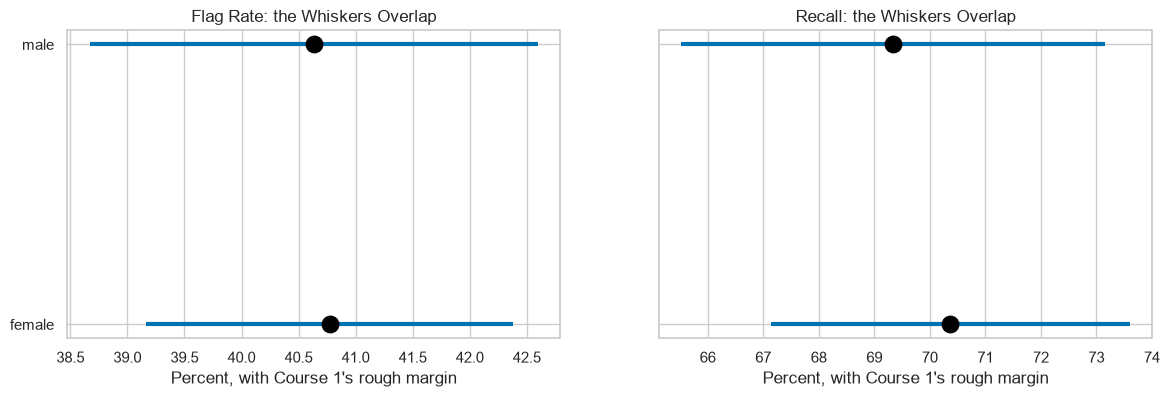

In [40]:
# each label's rate as a dot with its margin as a whisker, flag rate and recall side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, rate, margin, title in [(axes[0], "flag_rate", "flag_margin", "Flag Rate"), (axes[1], "recall", "recall_margin", "Recall")]:
    ax.hlines(by_label.index, (by_label[rate] - by_label[margin]) * 100, (by_label[rate] + by_label[margin]) * 100, linewidth=3)
    ax.scatter(by_label[rate] * 100, by_label.index, s=140, color="black", zorder=3)
    ax.set_xlabel("Percent, with Course 1's rough margin")
    ax.set_title(title + ": the Whiskers Overlap")
plt.show()

Flag rates of 40.77 percent for the female label and 40.63 for the male, recall of 70.37 and 69.34 percent: both gaps sit well inside the margins.

Course 1's Consumer Credit case study said of this file's rates by group that they "explain nothing and are no basis for treating people differently", and that holds here too.

Published fairness measures exist and can disagree with each other; the course certifies no model as fair.

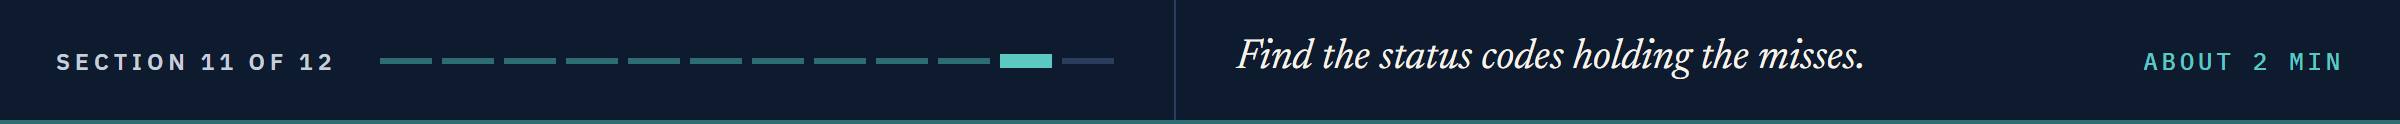

# Where the Model Fails

Q. At which September status codes does the pruned tree miss defaults, and where does it flag accounts that paid?

In [41]:
# the pruned tree's test accounts by September status (3 and above together): defaults caught, defaults missed, paid accounts flagged
status = card.loc[X_test.index, "PAY_0"].clip(upper=3)
outcomes = pd.DataFrame({"TP": (test_rows["defaulted"] == 1) & (test_rows["flagged"] == 1),
                         "FN": (test_rows["defaulted"] == 1) & (test_rows["flagged"] == 0),
                         "FP": (test_rows["defaulted"] == 0) & (test_rows["flagged"] == 1)}).groupby(status).sum()
outcomes

,TP,FN,FP
PAY_0,,,
-2,53,33,194
-1,125,76,320
0,110,270,440
1,201,20,364
2,361,0,168
3,78,0,29


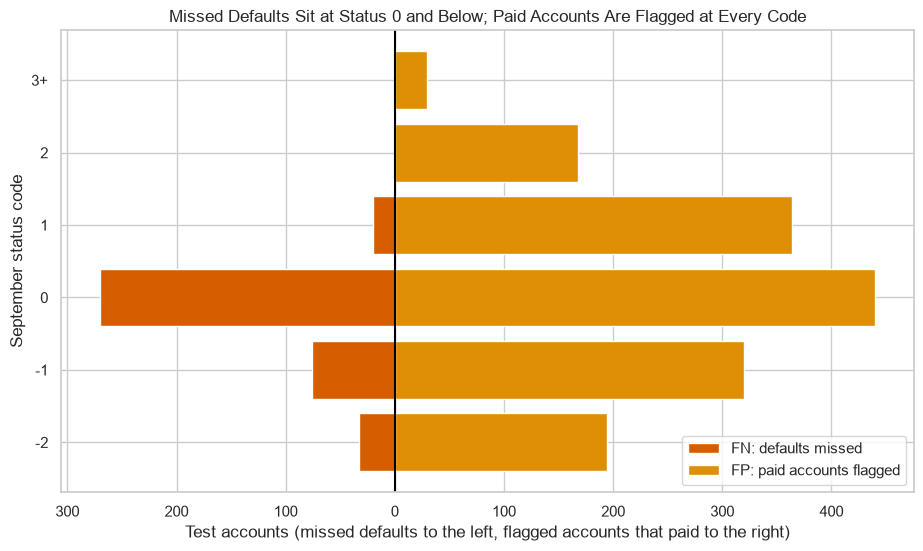

In [42]:
# a butterfly: missed defaults to the left of zero, paid accounts flagged to the right, one row per code
plt.figure(figsize=(11, 6))
plt.barh(outcomes.index, -outcomes["FN"], color=CELL_COLOURS["FN"], label="FN: defaults missed")
plt.barh(outcomes.index, outcomes["FP"], color=CELL_COLOURS["FP"], label="FP: paid accounts flagged")
plt.yticks(outcomes.index, ["-2", "-1", "0", "1", "2", "3+"])
plt.axvline(0, color="black")
plt.xticks(range(-300, 500, 100), [abs(tick) for tick in range(-300, 500, 100)])  # counts on both sides, without a minus sign
plt.xlabel("Test accounts (missed defaults to the left, flagged accounts that paid to the right)")
plt.ylabel("September status code")
plt.title("Missed Defaults Sit at Status 0 and Below; Paid Accounts Are Flagged at Every Code")
plt.legend(loc="lower right")
plt.show()

A **butterfly chart** sets two counts back to back on one axis.

379 of the 399 missed defaults sit at codes 0 or below, 270 at code 0.

Every default at code 2 or more is caught, 439 of them.

954 of the 1,515 flagged accounts that paid are at codes 0 or below.

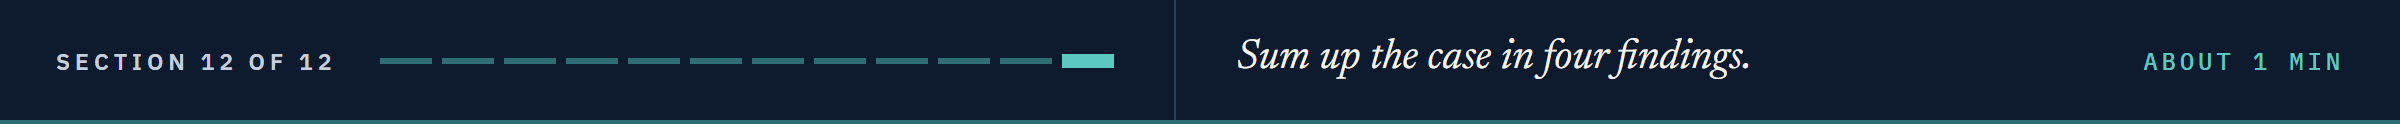

# Insights and Conclusion

**What it separates:** on unseen accounts the pruned tree ranks with ROC AUC 0.7544 and catches 69.9 percent of the defaults while flagging 40.7 percent of the accounts.

**Where it is wrong:** defaults with no delay in September, 379 of its 399 misses.

**What the data cannot support:** one place, one six-month window in 2005, and accounts chosen in a way the source does not describe.

**What was not tested:** another period, the calibration of the outputs, and any cost of an error.

**A model describes the file it was fitted on, and this one says September's status first and the rest a little.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Run a classification case study from the data to the test accounts, choosing everything on validation accounts.
* Tame heavy tails with `QuantileTransformer` inside a pipeline, and read a letter-value plot on a symlog axis.
* Choose a threshold for a recall target and compare models on a cumulative gains curve.
* Read a pruned tree's leaves with `.apply`, and describe a model's flags by group with a margin.
* Say where a model fails, and what its file cannot support.

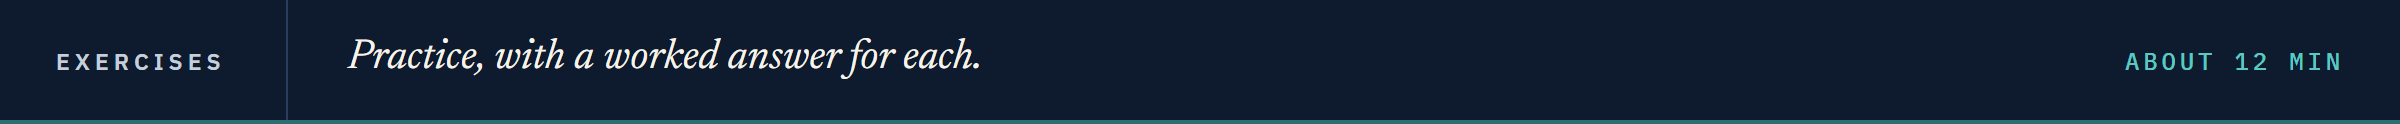

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [43]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Recall Target of 0.60**

Q. Choose each finalist's threshold for a recall of 0.60 with `threshold_for_recall`, on the validation accounts, and store the precision of its flags there in a dictionary `ex1_precision`, rounded to 4 decimals, with the keys `"quantile logistic"`, `"default tree"` and `"pruned tree"`.

In [44]:
# your code here
ex1_precision = ...

In [45]:
check("Exercise 1 precision at recall 0.60", ex1_precision, {"quantile logistic": 0.4264, "default tree": 0.2212, "pruned tree": 0.3938})

Exercise 1 precision at recall 0.60: not attempted yet


### Exercise 2

**The Pruned Tree With the Person Columns**

Q. Fit the pruned tree's settings (`ccp_alpha=0.001`, balanced weights, the seed) on the training accounts with the 19 features plus the four person columns.
Store its validation ROC AUC in `ex2_auc` and the four person columns' total impurity importance in `ex2_person_importance`.

In [46]:
# your code here
ex2_auc = ...
ex2_person_importance = ...

In [47]:
check("Exercise 2 the validation ROC AUC", ex2_auc, 0.7627296962089289)
check("Exercise 2 the person columns' importance", ex2_person_importance, 0.0)

Exercise 2 the validation ROC AUC: not attempted yet
Exercise 2 the person columns' importance: not attempted yet


### Exercise 3

**Lift in the Top Tenth**

The **lift** of a group is its default rate divided by the default rate of all the accounts.

Q. Take the tenth of the validation accounts with the highest quantile logistic output.
Store their default rate in `ex3_rate` and their lift in `ex3_lift`.

In [48]:
# your code here
ex3_rate = ...
ex3_lift = ...

In [49]:
check("Exercise 3 the default rate in the top tenth", ex3_rate, 0.5783333333333334)
check("Exercise 3 the lift", ex3_lift, 2.614920874152223)

Exercise 3 the default rate in the top tenth: not attempted yet
Exercise 3 the lift: not attempted yet


### Exercise 4: AI check

**A Balanced Split**

You asked an AI assistant for a 60/20/20 split with as many defaults as paid accounts.
`resample` from `sklearn.utils` draws rows with replacement, as Day 3's resampling did.
This came back.
It runs, and its default tree scores far better on its test rows than any model today.
Test it, then find the one bug.

In [50]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
from sklearn.utils import resample

def balanced_split(accounts):
    # defaults are rare, so copy defaults until both outcomes are equal, then split 60/20/20 with the seed
    defaults = accounts[accounts[TARGET] == 1]
    paid = accounts[accounts[TARGET] == 0]
    extra = resample(defaults, n_samples=len(paid) - len(defaults), replace=True, random_state=SEED)
    balanced = pd.concat([accounts, extra])
    rest, test = train_test_split(balanced, test_size=0.2, stratify=balanced[TARGET], random_state=SEED)
    train, valid = train_test_split(rest, test_size=0.25, stratify=rest[TARGET], random_state=SEED)
    return train, valid, test

In [51]:
# the default tree on the balanced split, scored on its test rows
ai_train, ai_valid, ai_test = balanced_split(card)
ai_tree = DecisionTreeClassifier(class_weight="balanced", random_state=SEED).fit(ai_train[FEATURES], ai_train[TARGET])
print("Test ROC AUC:", round(roc_auc_score(ai_test[TARGET], ai_tree.predict_proba(ai_test[FEATURES])[:, 1]), 4))

Test ROC AUC: 0.8518


In [52]:
# the test: no account may be in both the training rows and the test rows
shared = set(ai_train["ID"]) & set(ai_test["ID"])
assert len(shared) == 0, f"{len(shared):,} accounts are in both the training and the test rows"

AssertionError: 3,032 accounts are in both the training and the test rows

Q. Fix the function: split first, then copy defaults into the training rows only.
Store the number of training rows the fixed function returns in `ex4_train_rows`, and the accounts in both its training and test rows in `ex4_shared`.

In [53]:
# your code here
ex4_train_rows = ...
ex4_shared = ...

In [54]:
check("Exercise 4 the training rows", ex4_train_rows, 28036)
check("Exercise 4 the shared accounts", ex4_shared, 0)

Exercise 4 the training rows: not attempted yet
Exercise 4 the shared accounts: not attempted yet


## Congratulations!

You ran a whole classification job once, the way a write-up runs it.
You tamed tails hundreds of times their median, set a logistic regression against two trees, and chose a model and a threshold on validation accounts alone.
Then you opened the test accounts once, and the numbers held.
You described the model's flags by group with a margin, and found where it fails: defaults with no delay in September.
Week 3 adds the calendar: data with dates, and validation that walks forward through time.

[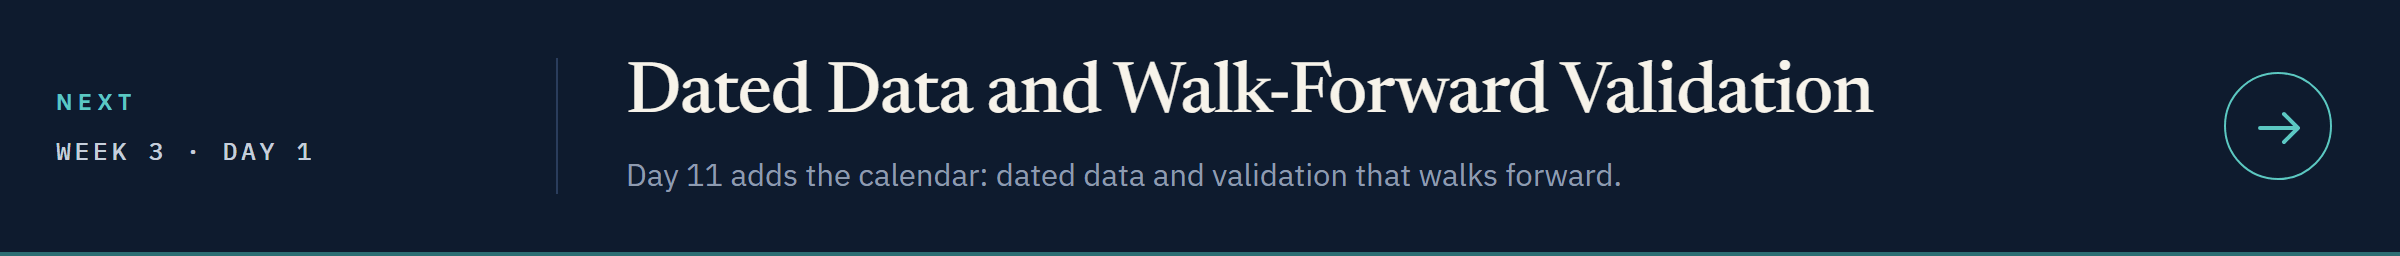](../../week3/day1/11_dated_data_and_walk_forward_validation.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day1/11_dated_data_and_walk_forward_validation.ipynb)